<a href="https://colab.research.google.com/github/kirtheeshj/Aiml-assignment-/blob/main/Copy_of_World_Energy_Consumption_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

In [ ]:
df = pd.read_csv("/content/World_Energy_By_Country_And_Region_1965_to_2023.csv")

print(df.head())
print(df.columns.tolist())

               Country   1965   1966   1967   1968   1969   1970   1971  \
0                  NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1               Canada   5.00   5.32   5.57   5.92   6.28   6.73   6.94   
2               Mexico   1.06   1.12   1.14   1.24   1.36   1.45   1.53   
3                   US  51.98  54.89  56.80  60.19  63.30  65.54  66.92   
4  Total North America  58.04  61.33  63.51  67.36  70.95  73.72  75.39   

    1972   1973  ...    2014    2015    2016    2017    2018    2019    2020  \
0    NaN    NaN  ...     NaN     NaN     NaN     NaN     NaN     NaN     NaN   
1   7.47   8.11  ...   14.43   14.47   14.34   14.54   14.72   14.64   13.76   
2   1.69   1.82  ...    8.03    7.94    8.11    8.26    8.15    8.07    7.35   
3  70.25  73.22  ...   93.59   92.69   92.62   92.97   96.37   95.68   88.64   
4  79.41  83.16  ...  116.04  115.10  115.07  115.76  119.25  118.40  109.75   

     2021    2022    2023  
0     NaN     NaN     NaN  
1   13.92   

In [ ]:
# Filter the row for India (using 'Country' with a capital 'C')
india_row = df[df["Country"] == "India"].copy()

# Reshape the data from wide format (years as columns) to long format
india = pd.melt(
    india_row,
    id_vars=["Country"],
    var_name="year",
    value_name="primary_energy_consumption"
)

# Convert columns to numeric types
india["year"] = pd.to_numeric(
    india["year"], errors="coerce"
)

india["primary_energy_consumption"] = pd.to_numeric(
    india["primary_energy_consumption"], errors="coerce"
)

# Drop missing values
india = india.dropna(
    subset=["year", "primary_energy_consumption"]
)

# Sort and clean up
india = india.sort_values("year")
india["year"] = india["year"].astype(int)

# Select only the relevant columns
india = india[["year", "primary_energy_consumption"]]

print(india.head())
print(india.tail())
print("Total records:", len(india))

   year  primary_energy_consumption
0  1965                        2.23
1  1966                        2.30
2  1967                        2.37
3  1968                        2.53
4  1969                        2.81
    year  primary_energy_consumption
54  2019                       33.54
55  2020                       31.78
56  2021                       34.51
57  2022                       36.37
58  2023                       39.02
Total records: 59


In [ ]:
values = india[
    "primary_energy_consumption"
].values.reshape(-1, 1)

split_index = int(len(values) * 0.8)

# Fit the scaler on all values to ensure proper scaling between [0, 1] for extrapolation
scaler = MinMaxScaler()
scaler.fit(values)

scaled_values = scaler.transform(values)

print(scaled_values[:5])

[[0.        ]
 [0.00190269]
 [0.00380538]
 [0.00815439]
 [0.01576515]]


In [ ]:
X = []
y = []
target_indices = []

for i in range(5, len(scaled_values)):
    X.append(scaled_values[i-5:i])
    y.append(scaled_values[i])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (54, 5, 1)
y shape: (54, 1)


In [ ]:
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 42
Testing samples: 12


In [ ]:
model = Sequential([
    SimpleRNN(
        50,
        activation="tanh",
        input_shape=(5, 1)
    ),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    shuffle=False,
    verbose=1
)

Epoch 1/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 1.7520e-04 - val_loss: 0.0185
Epoch 2/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 1.7151e-04 - val_loss: 0.0187
Epoch 3/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 1.6785e-04 - val_loss: 0.0189
Epoch 4/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 1.6420e-04 - val_loss: 0.0191
Epoch 5/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 1.6061e-04 - val_loss: 0.0193
Epoch 6/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 1.5703e-04 - val_loss: 0.0195
Epoch 7/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 1.5353e-04 - val_loss: 0.0198
Epoch 8/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 1.5003e-04 - val_loss: 0.0200
Epoch 9/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 1.4667e-04 - val_loss: 0.0202
Epoch 10/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 1.4324e-04 - val_loss: 0.0204
Epoch 11/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 1.4011e-04 - val_loss: 0.0206
Epoch 12/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 1

In [ ]:
predicted_scaled = model.predict(X_test)

actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(predicted_scaled)

print("Actual values:")
print(actual.flatten())

print("Predicted values:")
print(predicted.flatten())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
Actual values:
[25.02 25.84 27.59 28.55 29.83 30.96 32.72 33.54 31.78 34.51 36.37 39.02]
Predicted values:
[19.967682 20.499773 21.434004 21.626669 22.497955 23.088934 23.441645
 23.95816  24.730717 25.863245 24.381601 25.168026]


In [ ]:
mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 8.26
RMSE: 8.63


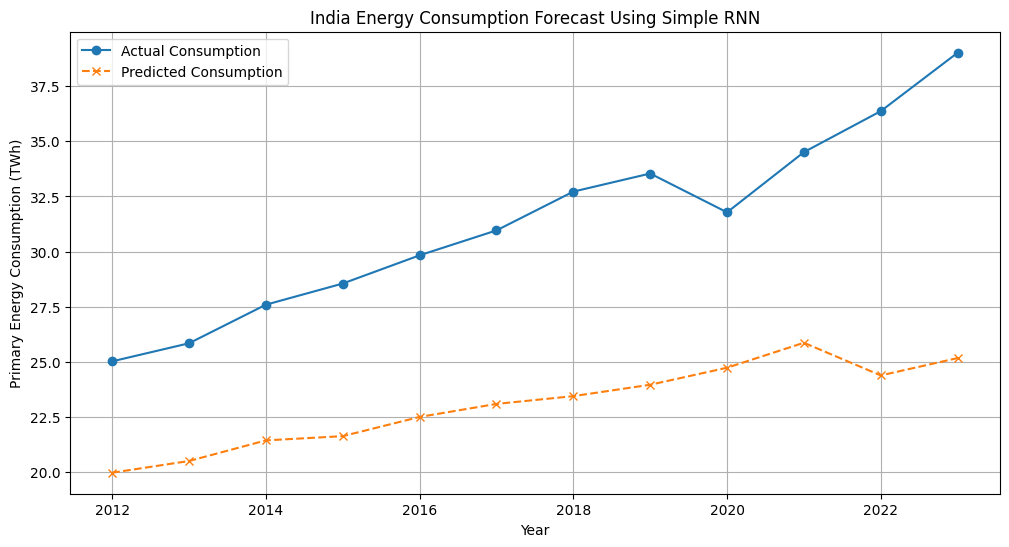

In [ ]:
test_years = india["year"].values[target_indices[test_mask]]

plt.figure(figsize=(12, 6))

plt.plot(
    test_years,
    actual.flatten(),
    marker="o",
    label="Actual Consumption"
)

plt.plot(
    test_years,
    predicted.flatten(),
    marker="x",
    linestyle="--",
    label="Predicted Consumption"
)

plt.title("India Energy Consumption Forecast Using Simple RNN")
plt.xlabel("Year")
plt.ylabel("Primary Energy Consumption (TWh)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

MAE: 8.256
RMSE: 8.6291


In [ ]:
results = pd.DataFrame({
    "Year": test_years,
    "Actual Consumption": actual.flatten(),
    "Predicted Consumption": predicted.flatten()
})

results["Absolute Error"] = abs(
    results["Actual Consumption"] -
    results["Predicted Consumption"]
)

print(results.round(2).to_string(index=False))

 Year  Actual Consumption  Predicted Consumption  Absolute Error
 2012               25.02              19.969999            5.05
 2013               25.84              20.500000            5.34
 2014               27.59              21.430000            6.16
 2015               28.55              21.629999            6.92
 2016               29.83              22.500000            7.33
 2017               30.96              23.090000            7.87
 2018               32.72              23.440001            9.28
 2019               33.54              23.959999            9.58
 2020               31.78              24.730000            7.05
 2021               34.51              25.860001            8.65
 2022               36.37              24.379999           11.99
 2023               39.02              25.170000           13.85


In [ ]:
# Use the last five years of data
last_five_years = scaled_values[-5:].reshape(1, 5, 1)

# Predict the next year
next_scaled = model.predict(last_five_years, verbose=0)

# Convert to the original scale
next_consumption = scaler.inverse_transform(next_scaled)[0, 0]

print("Last recorded year:", india["year"].iloc[-1])
print("Forecast year:", india["year"].iloc[-1] + 1)
print(
    "Predicted energy consumption:",
    round(next_consumption, 2)
)

Last recorded year: 2023
Forecast year: 2024
Predicted energy consumption: 32.07
